### 1. Import the libraries

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, r2_score

### 2. Download the stock data

In [2]:
# Use the same stock and date range as ARIMA.ipynb.
stk_data = yf.download("TATACONSUM.NS", start="2021-06-01", end="2022-01-05", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


### 3. Prepare the Open, High, Low, and Close columns

In [3]:
# Some yfinance versions return column names with multiple levels.
if stk_data.columns.nlevels > 1:
    stk_data.columns = stk_data.columns.get_level_values(0)

# Keep four related price series in date order and remove missing rows.
stk_data = stk_data[["Open", "High", "Low", "Close"]].sort_index().dropna()
stk_data.head()

Price,Open,High,Low,Close
Date,,,,
2021-06-01,635.153931,636.537200,626.568191,635.153931
2021-06-02,634.867785,643.692018,629.764063,642.547241
2021-06-03,644.884433,651.562231,642.261013,648.700317
2021-06-04,649.511125,658.192296,643.930418,655.330383
2021-06-07,658.240032,674.457540,655.664298,667.732056


### 4. Calculate daily price changes

In [4]:
# diff() calculates today's price minus the previous trading day's price.
# dropna() removes the first row, which has no previous price.
data1 = stk_data.diff().dropna()
data1.head()

Price,Open,High,Low,Close
Date,,,,
2021-06-02,-0.286145,7.154818,3.195872,7.393311
2021-06-03,10.016648,7.870212,12.496950,6.153076
2021-06-04,4.626692,6.630066,1.669406,6.630066
2021-06-07,8.728907,16.265244,11.733880,12.401672
2021-06-08,14.452712,8.013408,13.641802,10.016724


### 5. Split the data into training and test sets

In [5]:
# Use the first 80% for training and the remaining 20% for testing.
# Keep the original time order: do not shuffle time series data.
training_size = int(len(data1) * 0.80)
train = data1.iloc[:training_size]
test = data1.iloc[training_size:]

if len(train) < 20 or len(test) < 2:
    raise ValueError("Use a longer date range to train and evaluate the model.")

print("Training rows:", len(train))
print("Test rows:", len(test))

Training rows: 119
Test rows: 30


### 6. Check stationarity

In [6]:
# Check each training series without using the test data.
for column in train.columns:
    result = adfuller(train[column])
    print(column, "ADF p-value:", round(result[1], 4))

Open ADF p-value: 0.0
High ADF p-value: 0.0836
Low ADF p-value: 0.0
Close ADF p-value: 0.0


/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_3914/4006626769.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(train[column])
/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_3914/4006626769.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(train[column])
/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipyke

### 7. Create and train the VAR model

In [7]:
# Reset the date index for fitting because trading dates have gaps.
# Keep the original dates in train and test for plotting later.
model = VAR(train.reset_index(drop=True))
lag_order = 1
model_fit = model.fit(lag_order)

print(model_fit.summary())
print("Stable model:", model_fit.is_stable())

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 29, Oct, 2026
Time:                     16:34:36
--------------------------------------------------------------------
No. of Equations:         4.00000    BIC:                    14.3617
Nobs:                     118.000    HQIC:                   14.0828
Log likelihood:          -1469.37    FPE:                1.07985e+06
AIC:                      13.8921    Det(Omega_mle):         914681.
--------------------------------------------------------------------
Results for equation Open
              coefficient       std. error           t-stat            prob
---------------------------------------------------------------------------
const            0.022286         0.439572            0.051           0.960
L1.Open         -0.264292         0.062026           -4.261           0.000
L1.High          0.285845         0.084914            3.366           0.001
L1.Lo

### 8. Forecast the test period

In [8]:
# Start forecasting from the last observed training row.
# Forecast all test rows without updating the model with test observations.
last_values = train.to_numpy()[-lag_order:]
forecast_values = model_fit.forecast(y=last_values, steps=len(test))

# Attach the column names and actual test dates to the forecasts.
predictions = pd.DataFrame(forecast_values, index=test.index, columns=train.columns)
predictions.head()

Price,Open,High,Low,Close
Date,,,,
2021-11-24,9.523387,6.619836,2.292675,-0.756787
2021-11-25,-1.069253,-0.678352,1.219924,1.825416
2021-11-26,1.671220,2.026387,0.961199,1.000026
2021-11-29,1.033424,0.927464,1.304452,1.300414
2021-11-30,1.153786,1.413220,1.085774,1.167473


### 9. Evaluate the Close forecasts

In [9]:
# Compare actual and predicted daily changes in Close.
actual_close = test["Close"]
predicted_close = predictions["Close"]

mse = mean_squared_error(actual_close, predicted_close)
rmse = np.sqrt(mse)
r2 = r2_score(actual_close, predicted_close)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test R2 score:", r2)

# A simple baseline predicts no change in closing price.
baseline = np.zeros(len(test))
baseline_rmse = np.sqrt(mean_squared_error(actual_close, baseline))
print("Zero-change baseline RMSE:", baseline_rmse)

Test MSE: 166.28750712291654
Test RMSE: 12.895251340044386
Test R2 score: -0.07161110493915324
Zero-change baseline RMSE: 12.73064210035203


### 10. Plot actual and forecast daily changes

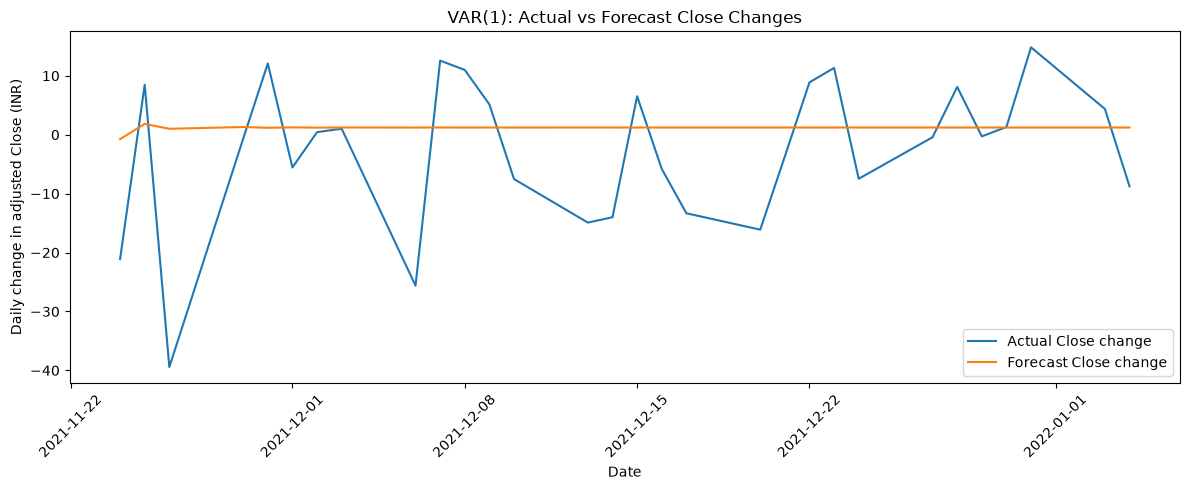

In [10]:
# How well the model predicts daily changes in Close.
plt.figure(figsize=(12, 5))
plt.plot(test.index, actual_close, label="Actual Close change")
plt.plot(test.index, predicted_close, label="Forecast Close change")
plt.title("VAR(1): Actual vs Forecast Close Changes")
plt.xlabel("Date")
plt.ylabel("Daily change in adjusted Close (INR)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()